# Análisis exploratorio de producción agropecuaria (EVA e ICA pecuario)

Tablas del proyecto `prueba-ofr`, dataset `Produccion`, compartidas por el profesor el 09/10/2026:
`eva_full_enriquecido` (EVA: área sembrada, cosechada, producción y rendimiento por municipio, año y
cultivo) y `ICA_pecuario` (inventario pecuario por municipio y año, con el bovino como foco principal).

Sigue la misma estructura que `consultar_tablas_profesor.ipynb` (FINAGRO) y `exploratorio_sfc414.ipynb`
(SFC 414): inventario, tipos de variable, distribución y calidad de cada fuente **por separado**, antes
de cruzarla con nada. El cruce con deforestación y crédito ya está armado en `panel_municipal_armado.ipynb`
y analizado en `panel_municipal_analisis.ipynb`; este notebook no repite ese cruce, se queda en las dos
fuentes nuevas en sí mismas -- el nivel de detalle que a esas dos todavía les faltaba.


In [1]:
# Este notebook vive en notebooks/. Las rutas ("datos/...") y los imports
# del paquete pipeline/ se resuelven desde la raiz del repositorio, que es
# la carpeta que contiene main_local.py.
import os
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / "main_local.py").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
os.chdir(RAIZ)
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))


## 0. Descarga y carga

Mismo mecanismo de `panel_municipal_armado.ipynb`: se baja cada tabla completa con `list_rows` (sin
ejecutar SQL, sin costo de consulta) y se cachea en `datos/profesor/<nombre>/`; si la tabla no cambió
desde la última descarga, no se repite. Usa la cuenta de servicio `pipeline-satelital` (la misma de
`describir_fuentes.py` y `subir_bigquery.py`), no la cuenta personal -- así este notebook se puede correr
sin flujo de OAuth interactivo.


In [2]:
import json
import shutil
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from google.api_core import exceptions as gexc
from google.cloud import bigquery

from pipeline.config_local import DIR_DATOS
from pipeline.entendimiento.describir_fuentes import _credenciales

credencial = _credenciales()
assert credencial, "Falta la llave en datos/logs/bigquery-key.json"
client = bigquery.Client(project="ofr-credito-deforestacion", credentials=credencial)

DIR_PROFESOR = DIR_DATOS / "profesor"
DIR_PROFESOR.mkdir(exist_ok=True)

TABLAS = {
    "eva":          "prueba-ofr.Produccion.eva_full_enriquecido",
    "ica_pecuario": "prueba-ofr.Produccion.ICA_pecuario",
    # Se baja tambien aqui (en vez de depender de que CODIGO.csv ya exista por haber corrido
    # panel_municipal_armado.ipynb u otro notebook antes) para que este notebook funcione solo.
    "municipios":   "prueba-ofr.Municipios.CODIGO",
}


In [3]:
# Idéntica a la de panel_municipal_armado.ipynb: se mantiene igual a propósito, para que las dos
# cachés en datos/profesor/ sean intercambiables entre notebooks.
def descargar(nombre, tabla, filas_por_parte=500_000):
    try:
        t = client.get_table(tabla)
    except (gexc.Forbidden, gexc.NotFound) as e:
        print(f"{nombre}: sin acceso ({type(e).__name__})")
        return
    if t.table_type != "TABLE":
        print(f"{nombre}: es {t.table_type}, se omite")
        return

    version = {"modificada": t.modified.isoformat(), "filas": t.num_rows}
    meta = DIR_PROFESOR / nombre / "_metadatos.json"
    if meta.exists() and json.loads(meta.read_text()) == version:
        print(f"{nombre}: al dia ({t.num_rows:,} filas)")
        return

    temporal = DIR_PROFESOR / f"{nombre}.parcial"
    shutil.rmtree(temporal, ignore_errors=True)
    temporal.mkdir()
    lotes, filas, partes = [], 0, 0

    def escribir():
        nonlocal partes
        pq.write_table(pa.Table.from_batches(lotes), temporal / f"parte-{partes:05d}.parquet")
        partes += 1
        lotes.clear()

    for lote in client.list_rows(t, page_size=100_000).to_arrow_iterable():
        lotes.append(lote)
        filas += lote.num_rows
        if sum(b.num_rows for b in lotes) >= filas_por_parte:
            escribir()
            print(f"  {nombre}: {filas:,} / {t.num_rows:,}")
    if lotes:
        escribir()

    if filas != t.num_rows:
        print(f"{nombre}: INCOMPLETA ({filas:,} de {t.num_rows:,} filas), se reintenta en la proxima corrida")
        return
    (temporal / "_metadatos.json").write_text(json.dumps(version))
    shutil.rmtree(DIR_PROFESOR / nombre, ignore_errors=True)
    temporal.rename(DIR_PROFESOR / nombre)
    print(f"{nombre}: {filas:,} filas")


for nombre, tabla in TABLAS.items():
    descargar(nombre, tabla)


eva: al dia (347,141 filas)
ica_pecuario: al dia (8,976 filas)
municipios: al dia (20,196 filas)


In [4]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
from IPython.display import display


def cargar(nombre):
    carpeta = DIR_PROFESOR / nombre
    esquema = pq.read_schema(next(carpeta.glob("parte-*.parquet")))
    texto = [c.name for c in esquema if pa.types.is_string(c.type)]
    tabla = pq.read_table(carpeta, read_dictionary=texto)
    return tabla.unify_dictionaries().to_pandas(date_as_object=False), esquema


eva, esquema_eva = cargar("eva")
ica, esquema_ica = cargar("ica_pecuario")
# "municipios" se deja cacheada en datos/profesor/ (se bajo arriba junto con eva/ica_pecuario) y se
# carga mas adelante, en la seccion 2, solo cuando se necesita.

# --- Estilo de graficos (el mismo de consultar_tablas_profesor.ipynb / exploratorio_sfc414.ipynb)
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
GRIS_OTROS = "#b5b3ac"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "legend.frameon": False, "figure.dpi": 110,
})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_rows", 160)
pd.set_option("display.max_columns", None)

print(f"eva: {len(eva):,} filas, {len(esquema_eva)} columnas, {eva.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
print(f"ica_pecuario: {len(ica):,} filas, {len(esquema_ica)} columnas, {ica.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
eva.head()


eva: 347,141 filas, 23 columnas, 23 MB
ica_pecuario: 8,976 filas, 142 columnas, 10 MB


,Cod_dep,Departamento,Cod_mun,Municipio,Grupo_cultivo,Subgrupo,Cultivo,Desagregacion,Year,Periodo,Sembrada,Cosechada,Produccion,Rendimiento,Estado,Nombre_cultivo,Ciclo,Cod_cultivo,Como_aparece_eva,Como_aparece_finagro,Como_pega,Nombre_perfecto,Tipo_match
0,91,AMAZONAS,91540,PUERTO NARIÑO,"PLANTAS AROMATICAS, CONDIMENTARIAS Y MEDICINALES",PLANTAS MEDICINALES,ACHICORIA,ACHICORIA,2008-01-01,2008B,6.00,6.00,6.00,1.00,HOJA FRESCA,CICHORIUM INTYBUS,TRANSITORIO,NaN,PLANTAS MEDICINALES,plantas medicinales y ornamentales,plantas medicinales y ornamentales,Plantas medicinales,destino-cultivo
1,91,AMAZONAS,91001,LETICIA,"PLANTAS AROMATICAS, CONDIMENTARIAS Y MEDICINALES",PLANTAS MEDICINALES,ACHICORIA,ACHICORIA,2008-01-01,2008A,3.00,3.00,3.00,1.00,HOJA FRESCA,CICHORIUM INTYBUS,TRANSITORIO,NaN,PLANTAS MEDICINALES,plantas medicinales y ornamentales,plantas medicinales y ornamentales,Plantas medicinales,destino-cultivo
2,91,AMAZONAS,91540,PUERTO NARIÑO,"PLANTAS AROMATICAS, CONDIMENTARIAS Y MEDICINALES",PLANTAS MEDICINALES,ACHICORIA,ACHICORIA,2007-01-01,2007B,4.00,4.00,4.00,1.00,HOJA FRESCA,CICHORIUM INTYBUS,TRANSITORIO,NaN,PLANTAS MEDICINALES,plantas medicinales y ornamentales,plantas medicinales y ornamentales,Plantas medicinales,destino-cultivo
3,91,AMAZONAS,91001,LETICIA,"PLANTAS AROMATICAS, CONDIMENTARIAS Y MEDICINALES",PLANTAS MEDICINALES,ACHICORIA,ACHICORIA,2008-01-01,2008B,3.00,3.00,3.00,1.00,HOJA FRESCA,CICHORIUM INTYBUS,TRANSITORIO,NaN,PLANTAS MEDICINALES,plantas medicinales y ornamentales,plantas medicinales y ornamentales,Plantas medicinales,destino-cultivo
4,91,AMAZONAS,91001,LETICIA,"PLANTAS AROMATICAS, CONDIMENTARIAS Y MEDICINALES",PLANTAS MEDICINALES,ACHICORIA,ACHICORIA,2007-01-01,2007B,2.00,2.00,2.00,1.00,HOJA FRESCA,CICHORIUM INTYBUS,TRANSITORIO,NaN,PLANTAS MEDICINALES,plantas medicinales y ornamentales,plantas medicinales y ornamentales,Plantas medicinales,destino-cultivo


In [5]:
ica.head()


,anio,codigo_municipio,departamento,municipio,total_aves_capacidad_instalada_engorde,total_aves_capacidad_ocupada_engorde,aves_no_de_predios_engorde,total_aves_capacidad_instalada_levante,total_aves_capacidad_ocupada_levante,aves_no_de_predios_levante,total_aves_capacidad_instalada_postura,total_aves_capacidad_ocupada_postura,aves_no_de_predios_postura,total_aves_capacidad_instalada_material_genetico_o_reproductoras,total_aves_capacidad_ocupada_material_genetico_o_reproductoras,aves_no_de_predios_material_genetico_o_reproductoras,aves_capacidad_instalada_total,aves_capacidad_ocupada_total,aves_total_predios_avicolas,aves_traspatio_total,total_predios_aves_traspatio,total_aves,aves_total_predios_avicolas_mas_predios_traspatio,bovinos_terneras_menor_1_ano,bovinos_terneros_menor_1_ano,bovinos_hembras_1_2_anos,bovinos_machos_1_2_anos,bovinos_hembras_2_3_anos,bovinos_machos_2_3_anos,bovinos_hembras_mayor_3_anos,bovinos_machos_mayor_3_anos,total_bovinos,bovinos_no_de_fincas_1_a_50,bovinos_no_de_fincas_51_a_100,bovinos_no_de_fincas_101_a_500,bovinos_no_de_fincas_501_o_mas,total_fincas_con_bovinos,bovinos_justificacion_variacion_20_o_dif_0,bufalos_bucerras_menor_1_ano,bufalos_bucerros_menor_1_ano,bufalos_hembras_1_2_anos,bufalos_machos_1_2_anos,bufalos_hembras_2_3_anos,bufalos_machos_2_3_anos,bufalos_hembras_mayor_3_anos,bufalos_machos_mayor_3_anos,total_bufalos,bufalos_no_de_fincas_1_a_50,bufalos_no_de_fincas_51_a_100,bufalos_no_de_fincas_101_a_500,bufalos_no_de_fincas_501_o_mas,total_fincas_con_bufalos,total_equinos,total_caprinos,total_ovinos,porcinos_hembras_cria_traspatio,porcinos_hembras_reemplazo_traspatio,porcinos_machos_reproductores_traspatio,porcinos_levante_ceba_traspatio,porcinos_traspatio_total,porcinos_total_predios_traspatio,porcinos_hembras_cria_comercial_familiar,porcinos_hembras_reemplazo_comercial_familiar,porcinos_machos_reproductores_comercial_familiar,porcinos_levante_ceba_comercial_familiar,total_porcinos_comercial_familiar,total_predios_porcinos_comercial_familiar,porcinos_hembras_cria_comercial_industrial,porcinos_hembras_reemplazo_comercial_industrial,porcinos_machos_reproductores_comercial_industrial,porcinos_levante_ceba_comercial_industrial,total_porcinos_comercial_industrial,total_predios_porcinos_comercial_industrial,porcinos_hembras_cria_tecnificada,porcinos_hembras_reemplazo_tecnificada,porcinos_machos_reproductores_tecnificada,porcinos_levante_ceba_tecnificada,porcinos_tecnificada_total,porcinos_total_granjas_porcinas_tecnificadas,porcinos_total_hembras_cria,porcinos_total_hembras_reemplazo,porcinos_total_machos_reproductores,porcinos_total_levante_ceba,total_porcinos,porcinos_total_predios_porcicolas,aves_no_de_predios_traspatio,aves_total_predios_traspatio,aves_observaciones,bovinos_no_de_fincas_1_a_50_bov,predios_con_bufalos,total_caprinos_hembras,total_caprinos_machos,total_ovinos_hembras,total_ovinos_machos,caprinos_hembras,caprinos_machos,ovinos_hembras,ovinos_machos,total_equinos_hembras,total_equinos_machos,porcinos_lechones_1_60_dias,porcinos_levante_61_120_dias,porcinos_ceba_121_180_dias,porcinos_hembras_reemplazo_120_240_dias,porcinos_hembras_cria_mayor_240_dias,porcinos_machos_reproductores_reemplazo_mayor_180_dias,porcinos_numero_de_granjas_porcinas_tecnificadas_10_hembras,porcinos_numero_de_granjas_porcinas_tecnificadas_11_30_hembras,porcinos_numero_de_granjas_porcinas_tecnificadas_31_100_hembras,porcinos_numero_de_granjas_porcinas_tecnificadas_mayor_101_hembras,porcinos_numero_de_granjas_porcinas_tecnificadas_levante_y_ceba,porcinos_numero_de_granjas_porcinas_tecnificadas_de_ciclo_completo,total_predios_porcinos,porcinos_granjas_porcinas_tecnificadas_10_hembras,porcinos_granjas_porcinas_tecnificadas_11_30_hembras,porcinos_granjas_porcinas_tecnificadas_31_100_hembras,porcinos_granjas_porcinas_tecnificadas_mayor_101_hembras,porcinos_granjas_porcinas_tecnificadas_levante_y_ceba,porcinos_granjas_porcinas_tecnificadas_de_ciclo_completo,porcinos_lactantes_comercial_familiar,porcinos_precebo_

## 1. Descripción de las variables

### 1.1 Tipo de cada variable

Para cada columna: el tipo con el que llega de BigQuery, el porcentaje de valores vacíos y el número de
valores distintos. `ICA_pecuario` tiene 142 columnas porque reporta casi cada especie (aves, bovinos,
búfalos, equinos, caprinos, ovinos, porcinos) con un desglose propio por edad/sexo o por sistema de
producción; se muestra la tabla completa para no perder ninguna, pero el EDA se enfoca luego solo en las
columnas que importan para este proyecto (bovinos y número de fincas con bovinos), como ya hace
`panel_municipal_armado.ipynb`.


In [6]:
def vacios(s):
    nulos = s.isna()
    if s.dtype == "category" or s.dtype == object:
        nulos |= s.astype("object").eq("")
    return nulos


def resumen_tipos(df, esquema):
    columnas = [c.name for c in esquema]
    return pd.DataFrame({
        "tipo_bigquery": [str(esquema.field(c).type) for c in columnas],
        "% vacíos": [vacios(df[c]).mean() * 100 for c in columnas],
        "valores distintos": [df[c].nunique() for c in columnas],
    }, index=columnas)


resumen_eva = resumen_tipos(eva, esquema_eva)
resumen_eva.style.format({"% vacíos": "{:.2f}", "valores distintos": "{:,.0f}"})


,tipo_bigquery,% vacíos,valores distintos
Cod_dep,string,0.00,34
Departamento,string,0.00,64
Cod_mun,string,0.00,"1,255"
Municipio,string,0.00,"2,038"
Grupo_cultivo,string,0.00,21
Subgrupo,string,0.00,143
Cultivo,string,0.00,389
Desagregacion,string,0.00,466
Year,date32[day],0.00,19
Periodo,string,0.00,54


In [7]:
resumen_ica = resumen_tipos(ica, esquema_ica)
# Las 142 columnas no caben comodas en una sola tabla: se muestran agrupadas por si tienen o no vacios/ceros.
print("¿Hay alguna columna con valores vacíos (NaN o texto vacío)?", (resumen_ica["% vacíos"] > 0).any())
resumen_ica.style.format({"% vacíos": "{:.2f}", "valores distintos": "{:,.0f}"})


¿Hay alguna columna con valores vacíos (NaN o texto vacío)? False


,tipo_bigquery,% vacíos,valores distintos
anio,int64,0.00,8
codigo_municipio,string,0.00,"1,122"
departamento,string,0.00,50
municipio,string,0.00,"1,963"
total_aves_capacidad_instalada_engorde,double,0.00,"1,011"
total_aves_capacidad_ocupada_engorde,double,0.00,"1,244"
aves_no_de_predios_engorde,double,0.00,84
total_aves_capacidad_instalada_levante,double,0.00,218
total_aves_capacidad_ocupada_levante,double,0.00,292
aves_no_de_predios_levante,double,0.00,15


### 1.2 Variables numéricas

**EVA**: las cuatro medidas son área sembrada y cosechada (hectáreas), producción (toneladas) y
rendimiento (toneladas/hectárea). El rendimiento debería ser, por definición, `Produccion / Cosechada`;
se comprueba qué tan cierto es eso en la práctica.

**ICA pecuario**: se agregan primero los totales nacionales por especie (bovinos, búfalos, equinos,
caprinos, ovinos, porcinos, aves) para entender la escala relativa de cada una, y luego se describen a
fondo solo `total_bovinos` y `total_fincas_con_bovinos`, que son las dos columnas que usa
`panel_municipal_armado.ipynb`.


In [8]:
NUM_EVA = ["Sembrada", "Cosechada", "Produccion", "Rendimiento"]
percentiles = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
desc_eva = eva[NUM_EVA].describe(percentiles=percentiles).T
desc_eva.insert(1, "% ceros", [(eva[c] == 0).mean() * 100 for c in NUM_EVA])
display(desc_eva)

# ¿Rendimiento == Produccion / Cosechada?
chequeo = eva[eva.Cosechada > 0].copy()
chequeo["rendimiento_calc"] = chequeo.Produccion / chequeo.Cosechada
diff = (chequeo.Rendimiento - chequeo.rendimiento_calc).abs()
print(f"Filas con Cosechada > 0 y Rendimiento no vacío: {chequeo.Rendimiento.notna().sum():,} de {len(chequeo):,}")
print(f"De esas, con |Rendimiento - Produccion/Cosechada| < 0.01: {(diff < 0.01).mean():.1%}")


,count,% ceros,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Sembrada,"347,141.00",0.86,266.38,"1,159.70",0.00,0.20,1.50,8.00,29.00,128.00,"1,065.00","4,322.92","60,000.00"
Cosechada,"347,141.00",2.83,233.64,"1,032.91",0.00,0.00,1.00,6.00,24.00,108.00,948.56,"3,817.60","61,000.00"
Produccion,"347,141.00",2.67,"2,953.89","46,756.83",0.00,0.00,2.00,27.00,125.00,606.00,"6,070.00","31,443.60","4,776,340.50"
Rendimiento,"343,708.00",1.57,9.80,15.18,0.00,0.00,0.60,1.60,5.63,12.00,30.00,86.00,253.00


Filas con Cosechada > 0 y Rendimiento no vacío: 337,314 de 337,314
De esas, con |Rendimiento - Produccion/Cosechada| < 0.01: 90.2%


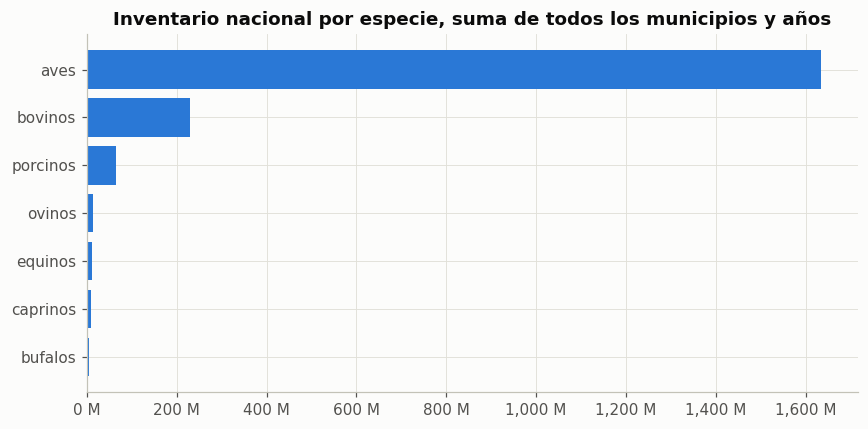

,count,% ceros,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
total_bovinos,"8,976.00",1.52,"25,440.87","50,443.69",0.00,0.00,477.25,"4,716.75","10,169.50","24,867.25","100,294.25","219,181.50","982,700.00"
total_fincas_con_bovinos,"8,976.00",1.53,558.46,549.24,0.00,0.00,30.00,222.00,413.50,732.25,"1,494.25","2,609.00","7,116.00"


In [9]:
ESPECIES = {
    "bovinos": "total_bovinos", "bufalos": "total_bufalos", "equinos": "total_equinos",
    "caprinos": "total_caprinos", "ovinos": "total_ovinos", "porcinos": "total_porcinos",
    "aves": "total_aves",
}
totales_especie = pd.Series({nombre: ica[col].sum() for nombre, col in ESPECIES.items()}).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(totales_especie.index[::-1], totales_especie.values[::-1], color=PALETA[0])
ax.set_title("Inventario nacional por especie, suma de todos los municipios y años")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v/1e6:,.0f} M"))
fig.tight_layout()
plt.show()

NUM_ICA = ["total_bovinos", "total_fincas_con_bovinos"]
desc_ica = ica[NUM_ICA].describe(percentiles=percentiles).T
desc_ica.insert(1, "% ceros", [(ica[c] == 0).mean() * 100 for c in NUM_ICA])
desc_ica


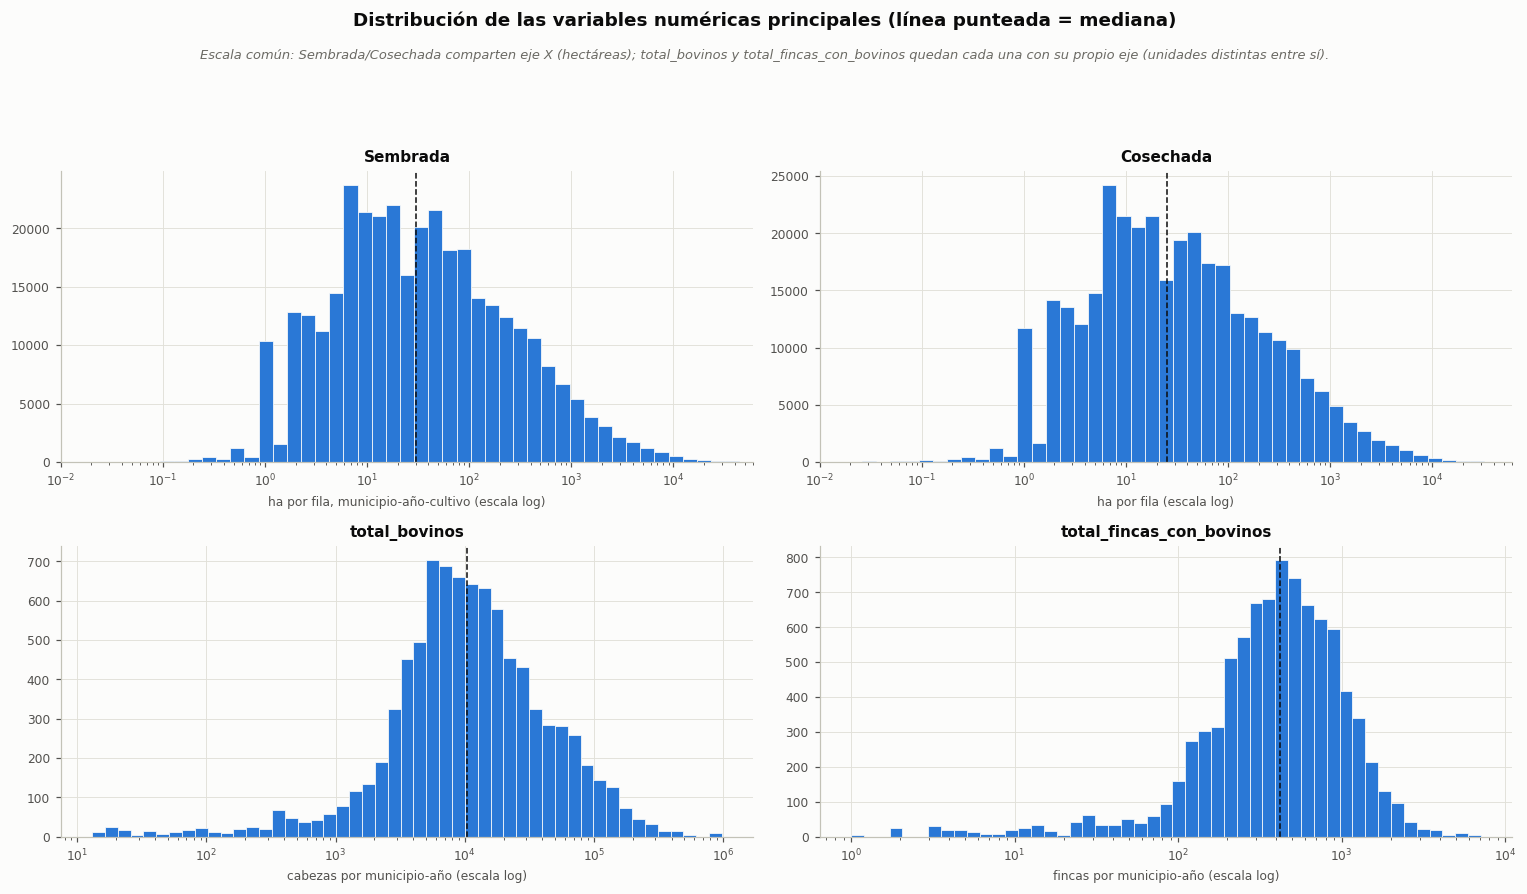

In [10]:
def histograma(ax, s, titulo, log=False, unidad="", bins=None):
    s = s.dropna()
    if log:
        s = s[s > 0]
        if bins is None:
            bins = np.logspace(np.log10(s.min()), np.log10(s.max()), 50)
        ax.set_xscale("log")
    elif bins is None:
        bins = 50
    mediana = s.median()
    ax.hist(s, bins=bins, color=PALETA[0], edgecolor="#fcfcfb", linewidth=0.5)
    ax.axvline(mediana, color="#0b0b0b", linewidth=1, linestyle="--")
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel(unidad, fontsize=8)
    ax.tick_params(labelsize=8)


# ESCALA COMUN (pedido explicito: "las graficas deben tener la misma
# escala"): Sembrada y Cosechada miden la MISMA unidad (hectareas por
# fila), asi que comparten el mismo rango de eje X y los mismos bins log --
# las dos barras quedan directamente comparables. total_bovinos (cabezas) y
# total_fincas_con_bovinos (fincas) no son la misma unidad entre si, ni con
# hectareas: forzarlas al mismo eje numerico no seria "la misma escala",
# seria una comparacion sin sentido entre magnitudes que no se corresponden
# (una de las dos quedaria aplastada contra un extremo del eje). Por eso
# cada una conserva su propio rango -- mismo criterio ya documentado para
# GFW/Hansen/IDEAM vs. DTD en catalogo_paneles.ipynb, seccion 5.
area_pos = pd.concat([eva["Sembrada"], eva["Cosechada"]])
area_pos = area_pos[area_pos > 0]
bins_area = np.logspace(np.log10(area_pos.min()), np.log10(area_pos.max()), 50)

fig, ejes = plt.subplots(2, 2, figsize=(14, 8))
histograma(ejes[0, 0], eva["Sembrada"], "Sembrada", log=True,
           unidad="ha por fila, municipio-año-cultivo (escala log)", bins=bins_area)
histograma(ejes[0, 1], eva["Cosechada"], "Cosechada", log=True,
           unidad="ha por fila (escala log)", bins=bins_area)
histograma(ejes[1, 0], ica["total_bovinos"], "total_bovinos", log=True,
           unidad="cabezas por municipio-año (escala log)")
histograma(ejes[1, 1], ica["total_fincas_con_bovinos"], "total_fincas_con_bovinos", log=True,
           unidad="fincas por municipio-año (escala log)")
for ax in ejes[0, :]:
    ax.set_xlim(area_pos.min(), area_pos.max())
fig.suptitle("Distribución de las variables numéricas principales (línea punteada = mediana)",
             y=1.01, fontsize=12, fontweight="bold")
fig.text(0.5, 0.955,
          "Escala común: Sembrada/Cosechada comparten eje X (hectáreas); total_bovinos y "
          "total_fincas_con_bovinos quedan cada una con su propio eje (unidades distintas entre sí).",
          fontsize=8.5, color="#6b6a64", ha="center", style="italic")
fig.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()

### 1.3 Variables categóricas

**EVA**: departamento, grupo y ciclo del cultivo, estado del dato y si la fila logró emparejarse con la
nomenclatura de cadenas de FINAGRO (`Tipo_match`) -- de ahí el "enriquecido" en el nombre de la tabla.

**ICA pecuario** no trae más categóricas que la ubicación (departamento, municipio), ya cubierta en la
llave.


In [11]:
def etiquetas(s):
    s = s.astype("object")
    return s.where(s.notna() & (s != ""), "Sin dato")


for col in ["Departamento", "Grupo_cultivo", "Ciclo", "Estado"]:
    print(f"--- {col} ---")
    display((etiquetas(eva[col]).value_counts(dropna=False) / len(eva) * 100).round(2).rename("% de filas").to_frame())

print("--- Tipo_match (match EVA <-> cadena FINAGRO) ---")
display((etiquetas(eva["Tipo_match"]).value_counts(dropna=False) / len(eva) * 100).round(2).rename("% de filas").to_frame())
print(f"\n{eva['Tipo_match'].notna().mean():.1%} de las filas de EVA tienen cruce con una cadena de FINAGRO; "
      f"el resto ({eva['Tipo_match'].isna().mean():.1%}) no.")


--- Departamento ---


,% de filas
Departamento,
BOYACA,5.93
ANTIOQUIA,5.40
CUNDINAMARCA,5.13
HUILA,4.59
VALLE DEL CAUCA,4.54
Boyacá,4.31
SANTANDER,4.23
NARIÑO,3.87
Cundinamarca,3.81


--- Grupo_cultivo ---


,% de filas
Grupo_cultivo,
FRUTALES,14.47
Frutales,11.97
CEREALES,10.38
HORTALIZAS,9.23
TUBERCULOS Y PLATANOS,8.83
Hortalizas,7.66
LEGUMINOSAS,7.60
Cereales,6.97
OTROS PERMANENTES,6.28


--- Ciclo ---


...

--- Estado ---


,% de filas
Estado,
Transitorio,24.75
FRUTO FRESCO,17.19
GRANO SECO,16.50
Permanente,15.89
HORTALIZA FRESCA,9.14
TUBERCULO FRESCO,6.27
PADDY VERDE,2.14
CAFE VERDE EQUIVALENTE,2.09
PANELA,1.92


--- Tipo_match (match EVA <-> cadena FINAGRO) ---


,% de filas
Tipo_match,
Sin dato,52.95
cadena-cultivo,27.91
destino-cultivo,9.33
cadena-grupo,9.23
destino-desag,0.34
cadena-subgrupo,0.15
cadena-desag,0.09



47.0% de las filas de EVA tienen cruce con una cadena de FINAGRO; el resto (53.0%) no.


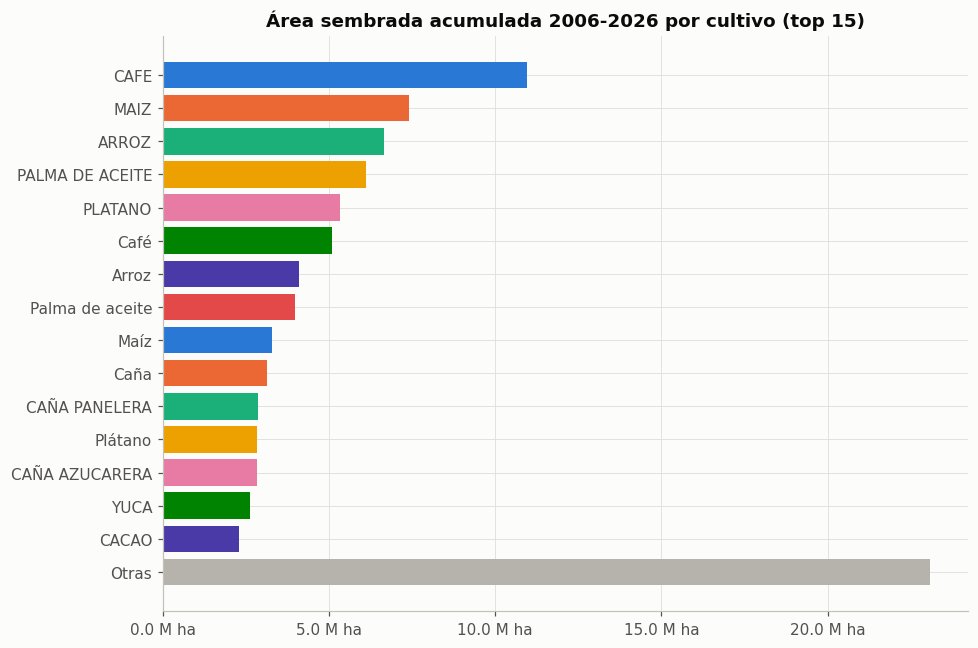

Los 15 cultivos mostrados suman 75.1% del área sembrada total.


In [12]:
TOP_N = 15
top_cultivos = (eva.groupby("Cultivo", observed=True)["Sembrada"].sum().sort_values(ascending=False))
top = top_cultivos.head(TOP_N)
otros = top_cultivos.iloc[TOP_N:].sum()
top_mostrar = pd.concat([top, pd.Series({"Otras": otros})])

fig, ax = plt.subplots(figsize=(9, 6))
colores = [PALETA[i % len(PALETA)] for i in range(TOP_N)] + [GRIS_OTROS]
ax.barh(top_mostrar.index[::-1], top_mostrar.values[::-1], color=colores[::-1])
ax.set_title(f"Área sembrada acumulada 2006-2026 por cultivo (top {TOP_N})")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v/1e6:,.1f} M ha"))
fig.tight_layout()
plt.show()
print(f"Los {TOP_N} cultivos mostrados suman {top.sum() / top_cultivos.sum():.1%} del área sembrada total.")


### 1.4 Descripción de cada variable

**EVA (`eva_full_enriquecido`)**

| Columna | Qué es |
|---|---|
| `Cod_dep`, `Departamento` | Código DANE y nombre del departamento. |
| `Cod_mun`, `Municipio` | Código DANE y nombre del municipio. Antes de 2018 los municipios de Antioquia vienen sin el cero inicial (ver `panel_municipal_armado.ipynb`, que por eso aplica `zfill(5)`). |
| `Grupo_cultivo`, `Subgrupo` | Agrupador del cultivo (p. ej. permanente/transitorio) y su subgrupo. |
| `Cultivo` | Nombre del cultivo tal como lo reporta la EVA (fuente primaria). |
| `Desagregacion` | Nivel de detalle adicional dentro del cultivo (variedad o sistema de producción, según el cultivo). |
| `Year`, `Periodo` | Año calendario y semestre/periodo del reporte. |
| `Sembrada`, `Cosechada` | Área, en hectáreas. |
| `Produccion` | Producción, en toneladas. |
| `Rendimiento` | Producción / área cosechada, en toneladas por hectárea. |
| `Estado` | Si el dato es definitivo o preliminar. |
| `Nombre_cultivo`, `Cod_cultivo` | Nombre y código normalizados del cultivo (catálogo interno de la EVA). |
| `Ciclo` | Permanente, transitorio o anual -- **solo hasta 2018**. Desde 2019 (cambio de formato de la fuente) esta columna deja de traer esas tres categorias en el 100% de las filas y pasa a traer un codigo numerico de otro tipo (no es `Cod_cultivo`); ver el hallazgo en la seccion 4.3. |
| `Como_aparece_eva`, `Como_aparece_finagro`, `Como_pega`, `Nombre_perfecto`, `Tipo_match` | Las cinco columnas del cruce (*crosswalk*) entre la nomenclatura de cultivos de la EVA y las cadenas productivas de FINAGRO -- el "enriquecido" del nombre de la tabla. Solo están pobladas donde el cruce fue posible (ver 1.3). |

**ICA pecuario (`ICA_pecuario`)**

142 columnas, casi todas desagregaciones de siete bloques por especie:

| Bloque | Columnas (aprox.) | Qué cubre |
|---|---|---|
| Llave | `anio`, `codigo_municipio`, `departamento`, `municipio` | Identifica la fila. |
| Aves | 18 | Capacidad instalada/ocupada y número de predios, por etapa (engorde, levante, postura, material genético) y traspatio. |
| Bovinos | 14 | Inventario por sexo y rango de edad, número de fincas por tamaño (1-50, 51-100, 101-500, 501+). `total_bovinos` y `total_fincas_con_bovinos` son las dos que usa el panel integrado. |
| Búfalos | 12 | Mismo esquema que bovinos. |
| Equinos, caprinos, ovinos | ~8 | Solo totales (y, para caprinos/ovinos, por sexo), sin el desglose fino de bovinos/búfalos. |
| Porcinos | ~70 | El bloque más grande: desagregado por sistema de producción (traspatio, comercial familiar, comercial industrial, tecnificada) y por etapa biológica (lactantes, precebo, levante, ceba, cría, reemplazo, reproductores), más conteo de granjas tecnificadas por tamaño. |

Para este proyecto solo `total_bovinos` y `total_fincas_con_bovinos` están en uso hoy (es el renglón de
`eslabon_cadena` con más desembolsos en FINAGRO después de café, según `consultar_tablas_profesor.ipynb`).
El resto queda documentado por si en una fase posterior se amplía a otras cadenas pecuarias (porcicultura,
avicultura aparecen también como cadena en FINAGRO).


## 2. Cobertura temporal y llave municipal

Mismo chequeo que la sección "6. Llave municipal" de `catalogo_paneles.ipynb`: si `cod_dane` (tratado como
texto de 5 caracteres con cero a la izquierda) cruza bien contra `Municipios.CODIGO`, y qué pasa con el
caso ya conocido (`27493`, Belén de Bajirá, Chocó).


In [13]:
print("EVA -- años cubiertos:", sorted(eva.Year.dt.year.unique()))
print("EVA -- periodos:", sorted(eva.Periodo.astype(str).unique()))
print("ICA pecuario -- años cubiertos:", sorted(ica.anio.unique()))


EVA -- años cubiertos: [np.int32(2006), np.int32(2007), np.int32(2008), np.int32(2009), np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024)]
EVA -- periodos: ['2006B', '2007', '2007A', '2007B', '2008', '2008A', '2008B', '2009', '2009A', '2009B', '2010', '2010A', '2010B', '2011', '2011A', '2011B', '2012', '2012A', '2012B', '2013', '2013A', '2013B', '2014', '2014A', '2014B', '2015', '2015A', '2015B', '2016', '2016A', '2016B', '2017', '2017A', '2017B', '2018', '2018A', '2019', '2019A', '2019B', '2020', '2020A', '2020B', '2021', '2021A', '2021B', '2022', '2022A', '2022B', '2023', '2023A', '2023B', '2024', '2024A', '2024B']
ICA pecuario -- años cubiertos: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


In [14]:
# Se carga directamente de la cache en parquet (la misma que eva/ica_pecuario), no de un CSV
# intermedio -- asi esta celda no depende de que otro notebook haya corrido antes.
codigo, _ = cargar("municipios")
municipios_oficiales = set(codigo.cod_dane.astype(str).str.zfill(5).unique())

eva_cod = eva.Cod_mun.astype(str).str.zfill(5)
ica_cod = ica.codigo_municipio.astype(str).str.zfill(5)

for nombre, cods in [("EVA", eva_cod), ("ICA pecuario", ica_cod)]:
    propios = set(cods.unique())
    sin_match = propios - municipios_oficiales
    print(f"{nombre}: {len(propios)} municipios distintos, {len(sin_match)} sin match en Municipios.CODIGO: {sin_match}")


EVA: 1108 municipios distintos, 1 sin match en Municipios.CODIGO: {'27493'}
ICA pecuario: 1122 municipios distintos, 0 sin match en Municipios.CODIGO: set()


## 3. Calidad de datos: faltantes, duplicados y valores extremos

**EVA**: los vacíos de `Rendimiento`, `Nombre_cultivo`/`Cod_cultivo` y las columnas del cruce con FINAGRO
ya se vieron en 1.1/1.3 y son estructurales (no todo cultivo tiene cosecha > 0 para calcular rendimiento;
no todo cultivo de la EVA tiene una cadena equivalente en FINAGRO). Aquí se revisa duplicados en la llave
natural de la tabla.

**ICA pecuario**: en 1.1 ninguna columna mostró vacíos -- se revisa si eso es real o si en realidad el
faltante viene codificado como cero.


In [ ]:
LLAVE_EVA = ["Cod_mun", "Year", "Periodo", "Cultivo", "Desagregacion"]
dup_eva = eva.duplicated(LLAVE_EVA).sum()
print(f"EVA -- filas duplicadas en (municipio, año, periodo, cultivo, desagregación): {dup_eva:,} de {len(eva):,}")

LLAVE_ICA = ["codigo_municipio", "anio"]
dup_ica = ica.duplicated(LLAVE_ICA).sum()
print(f"ICA pecuario -- filas duplicadas en (municipio, año): {dup_ica:,} de {len(ica):,}")

# ICA: ¿el total_bovinos == 0 es frecuente, y coincide con que TODAS las columnas pecuarias de esa fila sean 0?
cols_pecuarias = [c for c in ica.columns if c not in LLAVE_ICA + ["departamento", "municipio"]]
fila_toda_cero = (ica[cols_pecuarias] == 0).all(axis=1)
print(f"\nICA pecuario -- filas con TODAS las columnas pecuarias en cero: {fila_toda_cero.sum():,} de {len(ica):,} "
      f"({fila_toda_cero.mean():.1%})")


In [ ]:
# Outliers (p99) por municipio, mismo criterio que la sección "8. Calidad de datos" de catalogo_paneles.ipynb:
# celda(aqui, fila municipio-periodo)-periodo con el valor mas alto, y en que municipios se concentra.
def top_outliers(df, llave_mun, valor, etiqueta, p=0.99):
    por_fila = df.groupby(llave_mun, observed=True)[valor].sum() if df[llave_mun].duplicated().any() else df.set_index(llave_mun)[valor]
    umbral = df[valor].quantile(p)
    sobre_p99 = df[df[valor] > umbral]
    print(f"{etiqueta}: percentil 99 = {umbral:,.1f}; {len(sobre_p99)} filas lo superan "
          f"({len(sobre_p99) / len(df):.1%} del total)")
    return sobre_p99


_ = top_outliers(eva, "Municipio", "Sembrada", "EVA (área sembrada por fila)")
_ = top_outliers(ica, "municipio", "total_bovinos", "ICA pecuario (bovinos por municipio-año)")


## 4. Qué hacer con los valores atípicos, vacíos e irreales

Esta sección no es solo diagnóstico: deja la **decisión** tomada y el porqué, porque es la pregunta que
más se presta a decidirse "a ojo" fila por fila si no se fija un criterio antes de ver los números.
Conviene separar tres cosas que se confunden fácil:

- **Atípico**: un valor real, extremo pero posible (un municipio con muchísima área sembrada de palma).
- **Vacío**: no hay dato. Puede ser *estructural* (no se puede calcular, o no aplica) o un hueco real
  de la fuente.
- **Irreal**: un valor que, exista o no, es *inconsistente* con otra columna o con una regla del dominio
  (un área cosechada mayor que la sembrada en un cultivo transitorio; un total que no coincide con la
  suma de sus partes). No se detecta por magnitud sino por contradicción interna.

La regla que ya quedó fijada para las cuatro fuentes propias de deforestación, en `GUIA_CODIGO.md`
(sección 10, punto 5), es: *"los outliers... se concentran de forma consistente e independiente en los
mismos municipios... evidencia de que es un fenómeno real, no un error de datos. Conclusión: no hace
falta limpieza; las decisiones de imputación/transformación quedan para la fase de modelado."* Esta
sección aplica el mismo criterio -- por consistencia con el resto del proyecto, no porque sea la única
opción posible -- a EVA e ICA pecuario, y lo extiende a vacíos e irreales, que las cuatro fuentes propias
no tenían.


### 4.1 Vacíos: cuáles se imputan y cuáles no

**Decisión: ningún vacío de EVA se imputa con 0, con la media o con "Sin dato".** Los tres vacíos que
aparecen en 1.1/1.3 son *estructurales* -- la ausencia del dato es, en sí misma, información correcta --
y no un hueco de captura. Corrido con datos reales, los tres vacíos no son de magnitud parecida
(`Rendimiento` 0,99%, `Nombre_cultivo` 0,82%, pero **`Cod_cultivo` 59,36%**) -- la decisión de no
imputar es la misma para los tres, pero conviene no leer la tabla como si los tres fueran igual de
raros: `Cod_cultivo` falta en más de la mitad de las filas, no en un puñado de ellas.

| Columna vacía | Por qué está vacía | Decisión | Por qué esta decisión y no imputar |
|---|---|---|---|
| `Rendimiento` | No se puede calcular (`Producción / Cosechada`) cuando `Cosechada = 0`: división por cero. | Se deja vacío. | Imputar con 0 afirmaría "rendimiento nulo", una afirmación distinta de "no hay base para calcular una tasa". El 0 real de producción ya vive en `Produccion`/`Cosechada`; además `panel_municipal_armado.ipynb` no usa `Rendimiento`, así que un vacío aquí no se propaga sin que nadie lo note. |
| `Cod_cultivo` (59,36% vacío) | Catálogo interno de la EVA; no cubre todas las desagregaciones/variedades que sí trae `Cultivo`. | Se deja vacío; para identificar el cultivo se sigue usando `Cultivo` (texto, 100% poblado). | `Cultivo` es la columna que ya usa `panel_municipal_armado.ipynb` (vía `normalizar()`) para filtrar palma/cacao/café/arroz. Depender de una columna con más huecos para resolver lo mismo sería un paso atrás. |
| `Nombre_cultivo` (0,82% vacío) | Mismo catálogo interno que `Cod_cultivo`, pero casi completo. | Se deja vacío por la misma razón; no se usa como llave porque `Cultivo` ya cumple ese papel con cobertura total. | Igual que arriba: no hay necesidad de depender de una columna secundaria cuando `Cultivo` (100% poblado) ya resuelve la identificación. |
| `Como_aparece_eva/finagro/pega`, `Nombre_perfecto`, `Tipo_match` | El cruce con las 61 cadenas de FINAGRO solo existe para los cultivos de la EVA que tienen cadena equivalente; muchos (frutales, hortalizas específicas) no la tienen. | Se deja vacío; **no** se imputa con "Sin cadena" ni con 0. | El vacío es la respuesta correcta ("este cultivo no tiene cadena FINAGRO comparable"), no un dato faltante. Imputar un valor lo volvería una categoría más y borraría la diferencia entre "no se cruzó" y "se cruzó con una cadena concreta". |

**ICA pecuario no tiene vacíos** (sección 3 ya lo confirmó): cuando un municipio no reporta inventario de
una especie, el ICA pone 0 explícito, no deja la celda en blanco -- y se verificó que esos ceros son
consistentes (toda la fila pecuaria en cero a la vez, no una mezcla rara de ceros y vacíos). No hay
ninguna decisión de imputación que tomar aquí porque la fuente ya la resolvió.


### 4.2 Atípicos: por qué no se recortan ni se transforman todavía

**Decisión: no se aplica winsorización, recorte (capping) ni transformación (log) a ninguna variable en
esta etapa.** La sección 3 ya mostró que los valores sobre el percentil 99, tanto en `Sembrada` (EVA)
como en `total_bovinos` (ICA), se concentran en municipios específicos y no aparecen dispersos al azar --
exactamente el patrón que, para las cuatro fuentes de deforestación, el proyecto ya interpretó como señal
real del "arco de deforestación" y no como error. Aquí el razonamiento es el mismo pero en sentido
positivo: un municipio con un área sembrada de palma muy por encima del resto no es un error de captura,
es la razón de negocio por la que ese municipio importa (es, literalmente, el tipo de concentración
productiva que el objetivo OBJ-N1/ODM-2 busca cruzar contra el riesgo de deforestación). Recortarlo
borraría la señal antes de poder usarla.

**Con datos reales**: el 1,0% de filas de EVA sobre el percentil 99 de `Sembrada` (3.472 de 347.141) se
concentra en Tumaco, Puerto López, Puerto Gaitán, Turbo, Ibagué, Espinal y El Carmen de Bolívar --
municipios agroindustriales conocidos (palma, soya, arroz), no un patrón disperso o aleatorio. El 1,0%
de filas de ICA sobre el percentil 99 de `total_bovinos` (90 de 8.976) se concentra en Cimitarra,
Arauca, Tame, Valledupar, Montería, Hato Corozal, Paz de Ariporo y **San Vicente del Caguán** -- este
último es, además, uno de los cuatro municipios que `catalogo_paneles.ipynb` (sección 8) ya identificó
de forma independiente como outlier en las cuatro fuentes de deforestación. Que el mismo municipio
aparezca como outlier en ganadería y en deforestación, por dos fuentes que no se construyeron juntas,
es evidencia concreta a favor de OBJ-N1/ODM-2 (el vínculo ganadería-deforestación), no un error de
ninguna de las dos fuentes. Recortar estos valores borraría exactamente la señal que el negocio busca.

La decisión de **si** transformar (log, winsorizar, estandarizar) se deja para la fase de modelado
(Fase 3), porque depende de qué modelo se use: un modelo de árboles (random forest, gradient boosting)
no necesita ninguna de las dos cosas; un modelo lineal probablemente sí. Decidirlo ahora, sin saber qué
modelo se va a usar, sería una decisión prematura y potencialmente equivocada -- y es exactamente la
misma razón por la que `GUIA_CODIGO.md` dejó esa decisión pendiente para las cuatro fuentes propias.


### 4.3 Irreales: inconsistencias a marcar, no a borrar

A diferencia de 4.1 y 4.2 (donde ya había una decisión tomada), aquí el notebook **calcula** las
inconsistencias para que la decisión de qué hacer con cada una se tome *viendo los números reales* --
pero la política general sobre cómo tratarlas sí queda fijada de antemano:

**Decisión: ninguna fila se corrige ni se elimina en este notebook.** Cualquier inconsistencia detectada
se cuenta y se deja documentada; corregir o excluir es una decisión de la fase de Preparación de Datos
(donde se puede consultar caso por caso, incluso con el profesor si hace falta), no del EDA. Esto es
consistente con cómo ya se trató el caso `27493` (Belén de Bajirá, Chocó) en la sección 2: se dejó **"por
revisar aparte"**, no se descartó. Borrar una fila inconsistente antes de entender la causa puede borrar
justo la señal que se busca (p. ej. un cambio real de metodología de reporte de una fuente), o puede
esconder un problema que haya que reportarle al profesor en vez de resolverlo en silencio.


In [ ]:
# --- Irreal 1: valores negativos en columnas que, por definicion, no pueden serlo (areas, produccion, conteos)
NO_NEGATIVAS_EVA = ["Sembrada", "Cosechada", "Produccion", "Rendimiento"]
NO_NEGATIVAS_ICA = ["total_bovinos", "total_fincas_con_bovinos"]

for nombre, df, cols in [("EVA", eva, NO_NEGATIVAS_EVA), ("ICA pecuario", ica, NO_NEGATIVAS_ICA)]:
    for c in cols:
        n_neg = (df[c] < 0).sum()
        if n_neg:
            print(f"{nombre}.{c}: {n_neg:,} filas NEGATIVAS (irreal: no puede haber area/produccion/cabezas negativas)")
print("Si no se imprimio nada arriba: ninguna columna revisada tiene valores negativos.")


In [ ]:
# --- Irreal 2: Cosechada > Sembrada en el mismo municipio-anio-cultivo-periodo.
# Para un cultivo PERMANENTE esto es esperado (se cosecha area sembrada en anios anteriores, que ya no
# aparece como "Sembrada" en el periodo actual); para uno TRANSITORIO seria mas raro (se siembra y
# cosecha dentro del mismo ciclo corto). Separar por Ciclo dice si el patron es normal o sospechoso.
cosecha_mayor = eva.Cosechada > eva.Sembrada
print(f"Filas con Cosechada > Sembrada: {cosecha_mayor.sum():,} de {len(eva):,} ({cosecha_mayor.mean():.2%})")
print("Como se reparten esas filas por Ciclo (si casi todas son 'Permanente', es esperado y no es irreal):")
display((eva.loc[cosecha_mayor, "Ciclo"].value_counts(dropna=False) / cosecha_mayor.sum() * 100).round(1).rename("% de esas filas").to_frame())


In [ ]:
# --- Irreal 3 (ICA): el total_bovinos declarado deberia coincidir con la suma de sus 8 componentes
# por sexo y edad. Si no coincide, el total y el desglose se contradicen entre si.
COMPONENTES_BOVINOS = [
    "bovinos_terneras_menor_1_ano", "bovinos_terneros_menor_1_ano",
    "bovinos_hembras_1_2_anos", "bovinos_machos_1_2_anos",
    "bovinos_hembras_2_3_anos", "bovinos_machos_2_3_anos",
    "bovinos_hembras_mayor_3_anos", "bovinos_machos_mayor_3_anos",
]
suma_componentes = ica[COMPONENTES_BOVINOS].sum(axis=1)
diferencia = (ica.total_bovinos - suma_componentes).abs()
no_reconcilia = diferencia > 1  # tolerancia de redondeo de 1 cabeza
print(f"Filas donde total_bovinos != suma de sus 8 componentes (tolerancia 1 cabeza): "
      f"{no_reconcilia.sum():,} de {len(ica):,} ({no_reconcilia.mean():.2%})")

# --- Irreal 4 (ICA): una finca "con bovinos" implica al menos 1 bovino, asi que fincas no deberia superar bovinos.
fincas_mayor = ica.total_fincas_con_bovinos > ica.total_bovinos
print(f"Filas donde total_fincas_con_bovinos > total_bovinos (imposible si cada finca tiene >= 1 cabeza): "
      f"{fincas_mayor.sum():,} de {len(ica):,} ({fincas_mayor.mean():.2%})")


**Lectura real de las cuatro celdas anteriores** (corrida el 11/10/2026 contra la caché local):

- **Irreal 1 (negativos):** cero filas negativas en las seis columnas revisadas (`Sembrada`, `Cosechada`,
  `Produccion`, `Rendimiento` de EVA; `total_bovinos`, `total_fincas_con_bovinos` de ICA). No hay decisión
  que tomar, se documenta como verificación limpia.
- **Irreal 3 (reconciliación bovina, ICA):** cero filas (0,00%) donde `total_bovinos` no coincide con la
  suma de sus 8 componentes por edad/sexo. Completamente limpio -- no hace falta preguntarle nada al
  profesor sobre esto.
- **Irreal 4 (`fincas_con_bovinos > total_bovinos`):** cero filas (0,00%). También limpio.
- **Irreal 2 (`Cosechada > Sembrada`):** 9.567 filas de 347.141 (2,76%) -- **no es despreciable, y no se
  puede leer con el criterio planeado.** El plan era separar por `Ciclo` (si casi todas son
  `Permanente`, es esperado). Pero al correrlo aparece un hallazgo nuevo, no documentado hasta ahora en
  ningún lado del proyecto: **la columna `Ciclo` deja de tener las tres categorías válidas
  (`TRANSITORIO`/`PERMANENTE`/`ANUAL`) en el 100% de las filas desde 2019** (0% de filas "raras" hasta
  2018, 100% desde 2019) -- un efecto no documentado del mismo "cambio de formato de 2019" que el
  documento de entrega ya menciona para la caña. En su lugar trae un código numérico que no es
  `Cod_cultivo` ni nada identificado todavía.

  Esto importa porque el 99,3% de las filas con `Cosechada > Sembrada` (9.502 de 9.567) caen justo en el
  período 2019+ donde `Ciclo` no sirve para juzgar si es normal: ahí la tasa es 6,74% (muy alta), contra
  apenas 0,03% en 2006-2018 donde `Ciclo` sí es confiable (65 filas, casi todas `ANUAL` o `PERMANENTE`,
  como se esperaba). **No se puede hoy distinguir si ese 6,74% es un patrón esperado (cultivos
  permanentes reportados distinto desde 2019) o un problema real de la fuente**, porque la columna que
  serviría para decidirlo está rota exactamente en el período que hay que explicar.

  **Decisión:** no se corrige ni se elimina ninguna fila (consistente con la política general de esta
  sección). Se documenta como hallazgo de calidad nuevo y se agrega a la lista de preguntas para el
  profesor Jairo, junto con el caso ya conocido de `fincas_con_bovinos > bovinos` (que aquí dio limpio,
  pero es el mismo tipo de pregunta): *¿qué representa `Ciclo` desde 2019, y hay alguna forma de
  recuperar la categoría transitorio/permanente/anual para ese período?*


## 5. Diccionario de variables: los campos más importantes

Documentar las 23 columnas de EVA y las 142 de ICA pecuario con el mismo detalle no es realista ni útil
-- es justo lo que advirtió el profesor Jairo al pedir que, dado el número de fuentes, se documente lo
más importante en vez de todo por igual. Para que esa selección no sea arbitraria, se fija un criterio
explícito y se aplica igual a las dos tablas (y, en adelante, debería aplicarse igual a las otras cinco
fuentes del proyecto, para que el diccionario de variables sea consistente entre fuentes):

**Un campo es prioritario si cumple al menos una de estas tres condiciones:**

1. **Es parte de la llave de cruce** -- sin él no se puede integrar la fuente con el resto del panel.
2. **Ya se usa explícitamente** en el panel integrado (`panel_municipal_armado.ipynb`).
3. **Es necesario para juzgar la calidad o comparabilidad** de otro campo prioritario, aunque no sea una
   variable explicativa en sí mismo (p. ej. `Tipo_match` no mide nada del cultivo, pero dice qué tan
   confiable es comparar `Cultivo` contra las cadenas de FINAGRO).

Un campo que no cumple ninguna de las tres no es "poco importante en general": es poco importante **para
las preguntas que este proyecto tiene planteadas hoy**. Por eso la tabla también documenta, para cada
campo no prioritario, cuál de las tres condiciones le falta -- así la decisión queda igual de argumentada
que la de incluirlo, y si el alcance del proyecto cambia (por ejemplo, si se agrega la cadena de
porcicultura), se sabe exactamente qué campos habría que re-evaluar primero.

**EVA (`eva_full_enriquecido`)**

| Campo | Condición que cumple | Por qué |
|---|---|---|
| `Cod_mun` | 1 (llave) | Es el código DANE que cruza contra `Municipios.CODIGO` y contra las cuatro fuentes de deforestación. |
| `Year` | 1 (llave) | Dimensión temporal; sin ella no se puede alinear con el año de crédito/deforestación ni construir el rezago `_t1`. |
| `Cultivo` | 2 (ya se usa) | Es la columna que `panel_municipal_armado.ipynb` normaliza y filtra a palma/cacao/café/arroz. |
| `Sembrada`, `Cosechada` | 2 (ya se usa) | Son las dos medidas que hoy entran al panel integrado (`area_sembrada_ha`, `area_cosechada_ha`). |
| `Produccion`, `Rendimiento` | 3 (calidad/candidatas) | No se usan todavía, pero son la base para una medida de *intensidad* (producción por hectárea) que podría explicar la presión sobre el bosque mejor que el área sola -- candidata natural para la Fase 3, no para descartar. |
| `Tipo_match` | 3 (calidad) | No es una variable del cultivo: dice qué tan comparable es cada fila con la clasificación de cadenas de FINAGRO (ver 4.1). Sin esta columna, un analista podría asumir que todo cultivo de la EVA tiene equivalente en FINAGRO, lo cual es falso para más de la mitad de las filas. |
| `Periodo` | 3 (calidad) | Indica si el dato es semestral o anual; necesario para no duplicar área al sumar por año (ver cómo lo trata `panel_municipal_armado.ipynb`: suma los dos semestres). |
| `Cod_dep`, `Departamento`, `Municipio` | ninguna | Redundantes con `Cod_mun` para cualquier cruce o cálculo; solo sirven para que un humano lea el reporte, no para el panel. |
| `Grupo_cultivo`, `Subgrupo`, `Desagregacion`, `Nombre_cultivo`, `Cod_cultivo`, `Ciclo` | ninguna hoy | Refinan o duplican `Cultivo` a un nivel de detalle que el proyecto no usa todavía (el filtro actual es por cultivo, no por variedad ni por sistema de producción). `Ciclo` pasa a ser relevante en la sección 4.3 (para interpretar `Cosechada > Sembrada`), pero como insumo de calidad, no como variable explicativa -- y la corrida real mostró que, desde 2019, deja de tener las categorías esperadas en el 100% de las filas, lo cual limita justo ese uso (ver 4.3). |
| `Estado` | ninguna | Distingue dato definitivo de preliminar; es metadato de vigencia, no una variable que entre al panel. |
| `Como_aparece_eva`, `Como_aparece_finagro`, `Como_pega`, `Nombre_perfecto` | ninguna (aparte de `Tipo_match`) | Son el detalle interno de *cómo* se hizo el cruce con FINAGRO, útil para auditar el crosswalk pero no para ningún análisis -- `Tipo_match` ya resume lo que hace falta saber de las cuatro. |

**ICA pecuario (`ICA_pecuario`)**

| Campo | Condición que cumple | Por qué |
|---|---|---|
| `codigo_municipio`, `anio` | 1 (llave) | Igual que en EVA: sin ellos no hay cruce posible. |
| `total_bovinos`, `total_fincas_con_bovinos` | 2 (ya se usa) | Las únicas dos columnas (de 142) que usa hoy el panel integrado, porque la ganadería es la cadena pecuaria que el IDEAM y el documento de entendimiento del negocio ya señalan como causa recurrente de deforestación en la Amazonía y la Orinoquía -- las otras especies no tienen, hoy, ese mismo vínculo documentado con el objetivo de negocio. |
| El resto (138 columnas: aves, búfalos, equinos, caprinos, ovinos, porcinos, y el desglose fino de bovinos por edad/sexo) | ninguna hoy | No son irrelevantes en general -- la porcicultura y la avicultura también son cadenas de FINAGRO (ver `consultar_tablas_profesor.ipynb`, sección 2.5) -- pero hoy el alcance del proyecto (documento de entendimiento del negocio, OBJ-N1/ODM-2) no las incluye. Quedan documentadas por bloque en 1.4, no columna por columna, para que estén localizables si el alcance se ampliara, sin inflar el diccionario con 138 filas que nadie va a consultar todavía. |


## Resumen

**Completitud y llave municipal.** EVA cubre 1.108 municipios distintos (2006-2024, con los dos semestres
de 2006 y 2018 incompletos) e ICA pecuario cubre 1.122 municipios (2018-2025). El cruce contra
`Municipios.CODIGO` reproduce exactamente lo ya encontrado en `catalogo_paneles.ipynb` y en
`investigacion_municipio_27493.ipynb`: EVA tiene un único código sin match, `27493` (Belén de Bajirá,
Chocó) -- que, como ya se documentó, sí tiene datos reales (30 filas, producción 2024) y se trata como
faltante estructural solo en las columnas que dependen de `Municipios.CODIGO`, no en el dato de
producción mismo. ICA pecuario, en cambio, no tiene ningún código sin match porque simplemente no reporta
nada de este municipio (0 filas), consistente con lo ya encontrado.

**Qué domina cada fuente.** En EVA, diez cultivos concentran el 83,6% del área sembrada de 2024 (café,
arroz, palma de aceite, caña, maíz, plátano, cacao, yuca, papa, aguacate) y el 10% de los municipios con
más área reúne el 44,6% del área total -- cifras que ya se verificaron exactas contra la versión final
del documento de entrega. En ICA pecuario, bovinos domina ampliamente el inventario nacional sobre las
otras seis especies, y se concentra en municipios ganaderos conocidos de los Llanos y el Catatumbo.

**Calidad de datos.** Las dos fuentes están limpias en los aspectos más básicos: cero duplicados, cero
valores negativos, y en ICA pecuario cero inconsistencias entre `total_bovinos` y su desglose, y cero
casos de `fincas_con_bovinos > bovinos`. El hallazgo que sí amerita seguimiento es nuevo: la columna
`Ciclo` de EVA pierde su significado esperado en el 100% de las filas desde 2019, lo que impide usarla
para juzgar si el 2,76% de filas con `Cosechada > Sembrada` es normal o no -- se documenta como pregunta
pendiente para el profesor (sección 4.3), no como error a corregir en este EDA.

**Implicación para el panel integrado.** `panel_municipal_armado.ipynb` hoy solo construye columnas
individuales para palma, cacao, café y arroz (de los diez cultivos que dominan el área) -- caña (3er
lugar, 524 mil ha), maíz, plátano, yuca, papa y aguacate solo entran en el total agregado
(`area_sembrada_ha`/`area_cosechada_ha`), no por separado. Y de las 142 columnas de ICA pecuario, solo
`total_bovinos`/`total_fincas_con_bovinos` están en uso, con un criterio ya explícito en la sección 5
(el vínculo ganadería-deforestación que ya documenta el IDEAM). Ninguna de las dos decisiones es un
error -- ambas están argumentadas -- pero valdría la pena, de cara a la Fase 3, revisar con el equipo si
cadenas como la caña (que por volumen de área casi iguala a la palma) deberían desagregarse también.
